# Behaviour cloning and compounding error

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/03_behaviour_cloning.ipynb) &nbsp; Guide note: [guide-robot-learning-basics](https://www.matthewwnuk.com/guide-robot-learning-basics.html)

Behaviour cloning is supervised learning: observations in, the demonstrator's actions out. Its weakness
only shows when the policy runs in a loop and its own mistakes change what it sees next.

The task is small enough to run in seconds. A point robot must reach a target without touching a round
obstacle. An expert controller supplies the demonstrations.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

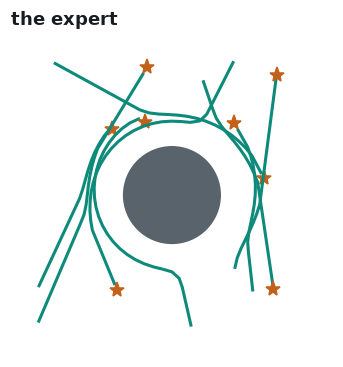

expert success: 100%


In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import toy, style
style.use(); rng = np.random.default_rng(0)
starts, targets = toy.test_set(300)                              # held-out start and target pairs
rate, paths, ok = toy.rollout(None, starts[:8], targets[:8], record=True)
plt.figure(figsize=(3.8, 3.8)); plt.gca().add_patch(plt.Circle(toy.C0, toy.R, color="#59636B"))
for k in range(8): plt.plot(paths[:, k, 0], paths[:, k, 1], color=style.TEAL); plt.plot(*targets[k], "*", color=style.ORANGE, ms=10)
plt.xlim(0, 1); plt.ylim(0, 1); plt.gca().set_aspect("equal"); style.bare(plt.gca()); plt.title("the expert"); plt.show()
print(f"expert success: {toy.rollout(None, starts, targets):.0%}")

## Train a policy

The policy sees its position and the target, and predicts the expert's action.

In [3]:
X, Y = toy.demonstrations(rng, 20, kind="absolute"); print("training pairs:", X.shape, Y.shape)
policy = toy.Policy().fit(X, Y)
Xh, Yh = toy.demonstrations(np.random.default_rng(1), 100, kind="absolute")
one_step = np.linalg.norm(policy.predict(Xh) - Yh, axis=1).mean()
print(f"one-step error on held-out expert states: {one_step * 100:.2f} cm  (each step is at most {toy.STEP * 100:.0f} cm)")
print(f"success when run in the loop: {toy.rollout(policy, starts, targets, kind='absolute'):.0%}")

training pairs: (499, 4) (499, 2)


one-step error on held-out expert states: 1.33 cm  (each step is at most 3 cm)
success when run in the loop: 33%


The one-step error looks small. The success rate does not look good. The gap is compounding error:
each mistake moves the policy to a state slightly further from the data, where the next mistake is larger.

## Watch it happen

Start the policy and the expert from the same places and track how far apart they get.

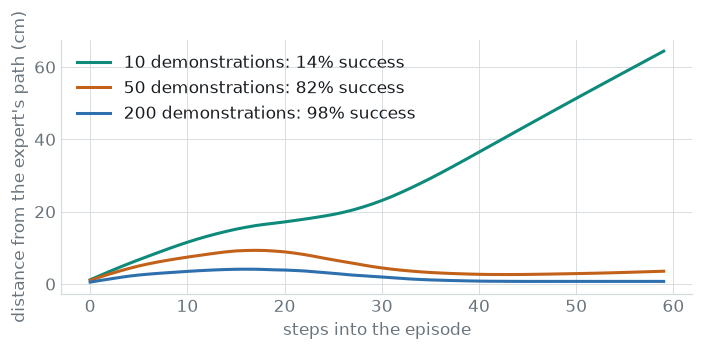

In [4]:
def deviation(policy, kind, steps=60):
    p_pol, p_exp = starts.copy(), starts.copy(); d = []
    for _ in range(steps):
        a = policy.predict(toy.features(p_pol, targets, kind)); n = np.linalg.norm(a, axis=1, keepdims=True); p_pol = p_pol + a * np.minimum(1, toy.STEP / np.maximum(n, 1e-9))
        p_exp = p_exp + toy.expert(p_exp, targets); d.append(np.linalg.norm(p_pol - p_exp, axis=1).mean() * 100)
    return d
plt.figure(figsize=(7.4, 3))
for n in (10, 50, 200):
    Xn, Yn = toy.demonstrations(np.random.default_rng(n), n, kind="absolute"); pol = toy.Policy().fit(Xn, Yn); d = deviation(pol, "absolute"); plt.plot(d, label=f"{n} demonstrations: {toy.rollout(pol, starts, targets, kind='absolute'):.0%} success")
plt.xlabel("steps into the episode"); plt.ylabel("distance from the expert's path (cm)"); plt.legend(); plt.show()

## Success against the amount of data, and two things that help

- **Recovery data**: nudge the demonstrator off course while recording, so the data shows how to get back.
- **Better inputs**: give the policy the target and obstacle positions relative to itself.

plain            ['8%', '14%', '30%', '77%', '91%', '99%']


+ recovery data  ['12%', '25%', '60%', '83%', '92%', '99%']


+ better inputs  ['10%', '21%', '47%', '82%', '94%', '99%']


+ both           ['18%', '39%', '68%', '87%', '97%', '100%']


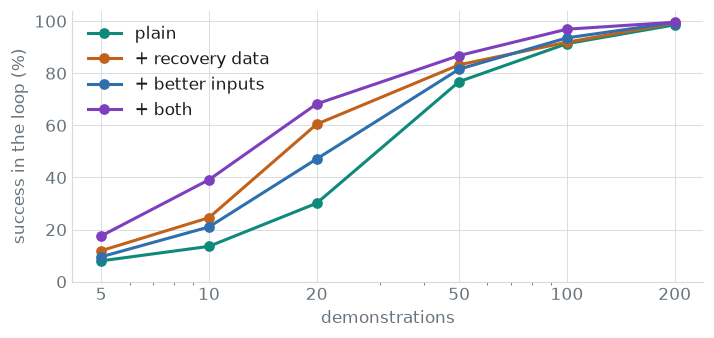

In [5]:
counts = [5, 10, 20, 50, 100, 200]; variants = {"plain": ("absolute", 0.0), "+ recovery data": ("absolute", 0.012), "+ better inputs": ("relative", 0.0), "+ both": ("relative", 0.012)}
plt.figure(figsize=(7.4, 3.2))
for name, (kind, noise) in variants.items():
    s = [np.mean([toy.rollout(toy.Policy(seed=sd).fit(*toy.demonstrations(np.random.default_rng(sd * 100 + n), n, kind, noise)), starts, targets, kind) for sd in range(3)]) * 100 for n in counts]
    plt.plot(counts, s, marker="o", label=name); print(f"{name:16s}", [f"{v:.0f}%" for v in s])
plt.xscale("log"); plt.xticks(counts, counts); plt.ylim(0, 104); plt.xlabel("demonstrations"); plt.ylabel("success in the loop (%)"); plt.legend(); plt.show()

## Action chunks

A chunking policy predicts several future actions at once and executes them before looking again.

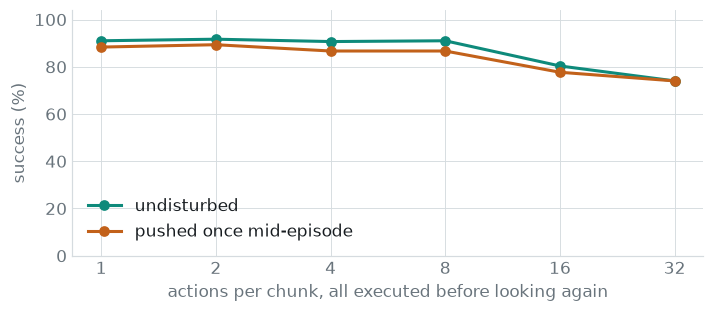

In [6]:
def run_chunks(pol, H, push=False, seed=0):
    r = np.random.default_rng(seed); p = starts.copy(); alive = np.ones(len(p), bool); ok = np.zeros(len(p), bool); when = r.integers(8, 30, len(p)); step = 0
    while step < 120:
        A = pol.predict(toy.features(p, targets, "relative")).reshape(len(p), H, 2)
        for h in range(H):
            a = A[:, h]; n = np.linalg.norm(a, axis=1, keepdims=True); p = np.where(alive[:, None], p + a * np.minimum(1, toy.STEP / np.maximum(n, 1e-9)), p)
            if push:
                ang = r.uniform(0, 2 * np.pi, len(p)); p = np.where((alive & (when == step))[:, None], p + 0.1 * np.stack([np.cos(ang), np.sin(ang)], 1), p)
            alive &= np.linalg.norm(p - toy.C0, axis=1) > toy.R; ok |= alive & (np.linalg.norm(p - targets, axis=1) < 0.03); alive &= ~ok; step += 1
    return ok.mean() * 100
Hs = [1, 2, 4, 8, 16, 32]; calm, pushed = [], []
for H in Hs:
    pol = toy.Policy(hidden=(96, 96)).fit(*toy.demonstrations(np.random.default_rng(40), 60, "relative", horizon=H)); calm.append(run_chunks(pol, H)); pushed.append(run_chunks(pol, H, push=True))
plt.figure(figsize=(7.4, 2.9)); plt.plot(Hs, calm, marker="o", label="undisturbed"); plt.plot(Hs, pushed, marker="o", label="pushed once mid-episode"); plt.xscale("log", base=2); plt.xticks(Hs, Hs); plt.ylim(0, 104)
plt.xlabel("actions per chunk, all executed before looking again"); plt.ylabel("success (%)"); plt.legend(); plt.show()

## Things to try

- Execute only the first half of each chunk before re-planning. How much reactivity does that buy back?
- Add noise to the policy's observations at test time. Which variant is most robust?
- Move the obstacle with `toy.set_obstacle([0.6, 0.4])` at test time only. Which input representation copes?